In [12]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc
import tensorflow as tf
from tensorflow import GradientTape as G_Tape
from IPython.display import display

print("=" * 70)
print("GOOGLE COLAB COMPUTATIONAL ENVIRONMENT CHECK")
print("=" * 70)
print(f"TensorFlow Version : {tf.__version__}")
print(f"Python Version     : {sys.version.split()[0]}")
print(f"NumPy Version      : {np.__version__}")
print(f"Pandas Version     : {pd.__version__}")

gpus = tf.config.list_physical_devices('GPU')
if not gpus:
    raise RuntimeError(
        "GPU not detected! Please go to Colab Menu -> Runtime -> Change runtime type -> "
        "select NVIDIA T4 GPU accelerator and re-run."
    )

print(f"Detected GPU(s)    : {gpus}")
try:
    gpu_name = tf.test.gpu_device_name()
    print(f"Active GPU Device  : {gpu_name}")
except Exception as e:
    print(f"GPU device name error: {e}")
print("=" * 70)

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')

GOOGLE COLAB COMPUTATIONAL ENVIRONMENT CHECK
TensorFlow Version : 2.21.0
Python Version     : 3.13.15
NumPy Version      : 2.1.3
Pandas Version     : 2.2.3
Detected GPU(s)    : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Active GPU Device  : /device:GPU:0


In [13]:
# Option financial parameters
n_dim = 2
T     = 3.0          # Maturity time in years
K     = 10.0         # Strike price
q     = 0.0          # Dividend yield
r     = 0.01         # Risk-free interest rate
S_max = 3.0 * K      # Upper spatial bound: S_max = 30.0
DTYPE = 'float32'

# Domain lower and upper bounds: [S1_min, S2_min, t_min] to [S1_max, S2_max, t_max]
lb = np.array([0.0, 0.0, 0.0], dtype=np.float32)
ub = np.array([S_max, S_max, T], dtype=np.float32)

print(f"Domain bounds:")
print(f"  Lower: S1={lb[0]}, S2={lb[1]}, t={lb[2]}")
print(f"  Upper: S1={ub[0]}, S2={ub[1]}, t={ub[2]}")

Domain bounds:
  Lower: S1=0.0, S2=0.0, t=0.0
  Upper: S1=30.0, S2=30.0, t=3.0


In [14]:
sigma_np = np.array([
    [0.05, 0.01],
    [0.01, 0.06]
], dtype=np.float32)

# Compute diffusion tensor alpha = sigma @ sigma.T (Paper formulation)
alphas_np = np.zeros((n_dim, n_dim), dtype=np.float32)
for i in range(n_dim):
    alphas_np[i, i] = np.sum(np.dot(sigma_np[i], sigma_np[i]))
    for j in range(i):
        alphas_np[i, j] = alphas_np[j, i] = np.sum(np.dot(sigma_np[i], sigma_np[j]))

print("=" * 70)
print("DIFFUSION TENSOR ALPHAS (sigma @ sigma.T)")
print("=" * 70)
print(f"Volatility Matrix sigma = \n{sigma_np}")
print(f"Diffusion Tensor alpha  = \n{alphas_np}")
print(f"alpha_11 = {alphas_np[0,0]:.6f}, alpha_22 = {alphas_np[1,1]:.6f}, alpha_12 = {alphas_np[0,1]:.6f}")
print("=" * 70)

alphas_tf = tf.constant(alphas_np, dtype=tf.float32)

DIFFUSION TENSOR ALPHAS (sigma @ sigma.T)
Volatility Matrix sigma = 
[[0.05 0.01]
 [0.01 0.06]]
Diffusion Tensor alpha  = 
[[0.0026 0.0011]
 [0.0011 0.0037]]
alpha_11 = 0.002600, alpha_22 = 0.003700, alpha_12 = 0.001100


In [15]:
def build_solution_network():
    """Builds the 2D Option Price Network V_theta(S1, S2, t)"""
    inputs = tf.keras.Input(shape=(3,), name="input_S1_S2_t")
    x = inputs
    for i in range(8):
        x = tf.keras.layers.Dense(
            20,
            activation="tanh",
            kernel_initializer=tf.keras.initializers.GlorotNormal(),
            name=f"sol_dense_{i+1}"
        )(x)
    outputs = tf.keras.layers.Dense(
        1,
        activation="linear",
        kernel_initializer=tf.keras.initializers.GlorotNormal(),
        name="sol_output_V"
    )(x)
    return tf.keras.Model(inputs=inputs, outputs=outputs, name="SolutionNetwork_2D")

def build_fb_network():
    """Builds the 2D Free-Boundary Network B_phi(t) = [B1(t), B2(t)]"""
    inputs = tf.keras.Input(shape=(1,), name="input_t")
    x = inputs
    for i in range(3):
        x = tf.keras.layers.Dense(
            100,
            activation="tanh",
            kernel_initializer=tf.keras.initializers.GlorotNormal(),
            name=f"fb_dense_{i+1}"
        )(x)
    outputs = tf.keras.layers.Dense(
        2,
        activation="linear",
        kernel_initializer=tf.keras.initializers.GlorotNormal(),
        name="fb_output_B"
    )(x)
    return tf.keras.Model(inputs=inputs, outputs=outputs, name="FreeBoundaryNetwork_2D")

# Display model summaries
sol_net_demo = build_solution_network()
fb_net_demo = build_fb_network()
print("Solution Network Summary:")
sol_net_demo.summary()
print("\nFree Boundary Network Summary:")
fb_net_demo.summary()

Solution Network Summary:


Model: "SolutionNetwork_2D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_S1_S2_t (InputLayer)      │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sol_dense_1 (Dense)             │ (None, 20)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sol_dense_2 (Dense)             │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sol_dense_3 (Dense)             │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sol_dense_4 (Dense)             │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sol_dense_5 (Dense)             │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sol_dense_6 (Dense)             │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sol_dense_7 (Dense)             │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sol_dense_8 (Dense)             │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sol_output_V (Dense)            │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,041 (11.88 KB)

 Trainable params: 3,041 (11.88 KB)

...

Model: "FreeBoundaryNetwork_2D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_t (InputLayer)            │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fb_dense_1 (Dense)              │ (None, 100)            │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fb_dense_2 (Dense)              │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fb_dense_3 (Dense)              │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fb_output_B (Dense)             │ (None, 2)              │           202 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,602 (80.48 KB)

 Trainable params: 20,602 (80.48 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
def sample_sobol_points(dim, n_points, lower_bound, upper_bound, seed=None):
    """Generates quasi-random collocation points using Sobol sequences."""
    sampler = qmc.Sobol(d=dim, scramble=False, seed=seed)
    pts = sampler.random(n=n_points)
    scaled = lower_bound + (upper_bound - lower_bound) * pts
    return tf.constant(scaled, dtype=tf.float32)

def sample_uniform_points(dim, n_points, lower_bound, upper_bound):
    """Generates uniform random points for validation."""
    pts = np.random.uniform(0.0, 1.0, size=(n_points, dim))
    scaled = lower_bound + (upper_bound - lower_bound) * pts
    return tf.constant(scaled, dtype=tf.float32)

# Exact Paper Allocation
N_f       = 60000    # PDE Collocation Points
N_init    = 1500     # Initial Condition Points
N_dir     = 1500     # Dirichlet Boundary Points
N_fb_init = 1        # Free Boundary Initial Condition Point
N_fb_dir  = 1500     # Free Boundary Dirichlet Points
N_fb_neu  = 1500     # Free Boundary Neumann Points

def generate_training_datasets():
    # 1. Unsupervised PDE Collocation Points
    pde_pts = sample_sobol_points(3, N_f, lb, ub)
    x_f_total = pde_pts[:, :2]
    t_f_total = pde_pts[:, 2:3]

    # 2. Initial Condition Points at t = T = 3.0
    init_spatial = sample_sobol_points(2, N_init, lb[:2], ub[:2])
    init_t = tf.fill((N_init, 1), tf.constant(T, dtype=tf.float32))
    x_init = tf.concat([init_spatial, init_t], axis=1)
    y_init = tf.nn.relu(K - tf.reduce_min(x_init[:, :2], axis=1))

    # 3. Dirichlet Outer Boundary Points (Half on S1=30, half on S2=30)
    n_half = N_dir // 2
    dir_face1_sub = sample_sobol_points(2, n_half, np.array([0.0, 0.0], dtype=np.float32), np.array([S_max, T], dtype=np.float32))
    dir_face1 = tf.concat([tf.fill((n_half, 1), tf.constant(S_max, dtype=tf.float32)), dir_face1_sub[:, 0:1], dir_face1_sub[:, 1:2]], axis=1) # [30, S2, t]

    dir_face2_sub = sample_sobol_points(2, n_half, np.array([0.0, 0.0], dtype=np.float32), np.array([S_max, T], dtype=np.float32))
    dir_face2 = tf.concat([dir_face2_sub[:, 0:1], tf.fill((n_half, 1), tf.constant(S_max, dtype=tf.float32)), dir_face2_sub[:, 1:2]], axis=1) # [S1, 30, t]

    x_dir = tf.concat([dir_face1, dir_face2], axis=0)
    S_min_dir = tf.reduce_min(x_dir[:, :2], axis=1)
    t_dir_vals = x_dir[:, 2]
    y_dir = tf.nn.relu(K * tf.exp(-r * (T - t_dir_vals)) - S_min_dir)

    # 4. Free Boundary Initial Condition at t = T
    t_fb_init = tf.constant([[T]], dtype=tf.float32)
    y_fb_init = tf.constant([[K, K]], dtype=tf.float32)

    # 5. Free Boundary Dirichlet & Neumann Points t in [0, T]
    t_fb_dir = sample_sobol_points(1, N_fb_dir, np.array([0.0], dtype=np.float32), np.array([T], dtype=np.float32))
    t_fb_neu = sample_sobol_points(1, N_fb_neu, np.array([0.0], dtype=np.float32), np.array([T], dtype=np.float32))

    return (
        x_f_total, t_f_total,
        x_init, y_init,
        x_dir, y_dir,
        t_fb_init, y_fb_init,
        t_fb_dir, t_fb_neu
    )

# Sample training data
(
    x_f_total, t_f_total,
    x_init, y_init,
    x_dir, y_dir,
    t_fb_init, y_fb_init,
    t_fb_dir, t_fb_neu
) = generate_training_datasets()

print("Training datasets instantiated successfully:")
print(f"  PDE Collocation Points   : {x_f_total.shape[0]} points (S1, S2 in [0, 30], t in [0, 3])")
print(f"  Initial Condition Points : {x_init.shape[0]} points at t=3.0")
print(f"  Dirichlet Boundary Points: {x_dir.shape[0]} points on S1=30, S2=30")
print(f"  FB Initial Point         : {t_fb_init.shape[0]} point at t=3.0 (Target: [10, 10])")
print(f"  FB Dirichlet Points      : {t_fb_dir.shape[0]} points")
print(f"  FB Neumann Points        : {t_fb_neu.shape[0]} points")

Training datasets instantiated successfully:
  PDE Collocation Points   : 60000 points (S1, S2 in [0, 30], t in [0, 3])
  Initial Condition Points : 1500 points at t=3.0
  Dirichlet Boundary Points: 1500 points on S1=30, S2=30
  FB Initial Point         : 1 point at t=3.0 (Target: [10, 10])
  FB Dirichlet Points      : 1500 points
  FB Neumann Points        : 1500 points


/tmp/ipykernel_8232/2770910381.py:4: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  pts = sampler.random(n=n_points)


In [17]:
def compute_2d_pde_residual(model, S1, S2, t_var):
    """
    Computes all first and second order derivatives using nested GradientTapes
    and returns the Black-Scholes PDE residual tensor.
    """
    with tf.GradientTape(persistent=True) as tape2:
        tape2.watch([S1, S2, t_var])
        with tf.GradientTape(persistent=True) as tape1:
            tape1.watch([S1, S2, t_var])
            inp = tf.concat([S1, S2, t_var], axis=1)
            V = model(inp, training=True)
        V_S1 = tape1.gradient(V, S1)
        V_S2 = tape1.gradient(V, S2)
        V_t  = tape1.gradient(V, t_var)

    V_S1S1 = tape2.gradient(V_S1, S1)
    V_S2S2 = tape2.gradient(V_S2, S2)
    V_S1S2 = tape2.gradient(V_S1, S2)

    del tape1
    del tape2

    pde_residual = (
        V_t
        + (r - q) * S1 * V_S1
        + (r - q) * S2 * V_S2
        + 0.5 * alphas_tf[0, 0] * (S1**2) * V_S1S1
        + alphas_tf[0, 1] * (S1 * S2) * V_S1S2
        + 0.5 * alphas_tf[1, 1] * (S2**2) * V_S2S2
        - r * V
    )

    return pde_residual, V, V_S1, V_S2, V_t, V_S1S1, V_S2S2, V_S1S2

In [18]:
print("=" * 70)
print("DIAGNOSTIC DERIVATIVE VERIFICATION")
print("=" * 70)

test_S1 = tf.constant(np.random.uniform(5.0, 25.0, (100, 1)), dtype=tf.float32)
test_S2 = tf.constant(np.random.uniform(5.0, 25.0, (100, 1)), dtype=tf.float32)
test_t  = tf.constant(np.random.uniform(0.1, 2.9, (100, 1)), dtype=tf.float32)

diag_mdl = build_solution_network()
res, v, v_s1, v_s2, v_t, v_s1s1, v_s2s2, v_s1s2 = compute_2d_pde_residual(diag_mdl, test_S1, test_S2, test_t)

derivatives_check = {
    "V (Option Value)": v,
    "V_S1 (Delta 1)": v_s1,
    "V_S2 (Delta 2)": v_s2,
    "V_t (Theta)": v_t,
    "V_S1S1 (Gamma 11)": v_s1s1,
    "V_S2S2 (Gamma 22)": v_s2s2,
    "V_S1S2 (Gamma 12 Cross)": v_s1s2,
    "PDE Residual": res
}

all_passed = True
for name, tensor in derivatives_check.items():
    is_valid = tensor is not None and not np.isnan(np.mean(tensor.numpy()))
    print(f"{name:<25}: Shape = {str(tensor.shape):<12} | Valid = {is_valid}")
    if not is_valid:
        all_passed = False

if not all_passed:
    raise RuntimeError("Diagnostic failed: One or more derivative tensors are None or NaN!")

diag_pde_loss = tf.reduce_mean(tf.square(res)).numpy()
print(f"\nInitial Diagnostic PDE Loss (MSE): {diag_pde_loss:.6f}")
print("Diagnostic verification completed successfully!")
print("=" * 70)

DIAGNOSTIC DERIVATIVE VERIFICATION
V (Option Value)         : Shape = (100, 1)     | Valid = True
V_S1 (Delta 1)           : Shape = (100, 1)     | Valid = True
V_S2 (Delta 2)           : Shape = (100, 1)     | Valid = True
V_t (Theta)              : Shape = (100, 1)     | Valid = True
V_S1S1 (Gamma 11)        : Shape = (100, 1)     | Valid = True
V_S2S2 (Gamma 22)        : Shape = (100, 1)     | Valid = True
V_S1S2 (Gamma 12 Cross)  : Shape = (100, 1)     | Valid = True
PDE Residual             : Shape = (100, 1)     | Valid = True

Initial Diagnostic PDE Loss (MSE): 0.000133
Diagnostic verification completed successfully!


In [19]:
class AmericanOptionPINN_2D:
    def __init__(self, seed=2):
        self.seed = seed
        tf.random.set_seed(seed)
        np.random.seed(seed)

        # Initialize Models
        self.mdl = build_solution_network()
        self.fb  = build_fb_network()

        # Initialize model variables with dummy inputs
        _ = self.mdl(tf.zeros((1, 3)))
        _ = self.fb(tf.zeros((1, 1)))

        # Learning Rate Schedules (Table 2)
        self.sol_lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
            initial_learning_rate=1e-2,
            decay_steps=400,
            decay_rate=0.9,
            staircase=False
        )
        self.fb_lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
            initial_learning_rate=1e-2,
            decay_steps=100,
            decay_rate=0.9,
            staircase=False
        )

        # Optimizers (Table 2: RMSprop)
        self.opt_sol = tf.keras.optimizers.RMSprop(learning_rate=self.sol_lr_schedule)
        self.opt_fb  = tf.keras.optimizers.RMSprop(learning_rate=self.fb_lr_schedule)

        # Build optimizers
        self.opt_sol.build(self.mdl.trainable_variables)
        self.opt_fb.build(self.fb.trainable_variables)

        # Early warning tracking for best weights (Paper lines 890-898)
        self.best_loss = np.inf
        self.best_sol_weights = None
        self.best_fb_weights = None
        self.best_epoch = 0

        # History storage
        self.history = {
            'epoch': [], 'unsup': [], 'init': [], 'dir': [],
            'fb_init': [], 'fb_dir': [], 'fb_neu': [],
            'free_boundary': [], 'solution': []
        }

    @tf.function
    def train_mdl_solo(self, x_f, t_f, x_init, y_init, x_dir, y_dir, t_fb_dir, t_fb_neu):
        """Single gradient update step for the Option Price Solution Network (Paper Lines 610-748)."""
        with tf.GradientTape() as mdl_tape:
            # Free boundary Dirichlet loss for solution network (INSIDE mdl_tape)
            s_values_dir = self.fb(t_fb_dir, training=False)
            fb_dc = self.mdl(tf.concat([s_values_dir, t_fb_dir], axis=1), training=True)
            fb_dir_target = tf.nn.relu(K - tf.reduce_min(s_values_dir, axis=1, keepdims=True))
            fb_dir_loss = tf.reduce_mean(tf.square(fb_dc - fb_dir_target))

            # Free boundary Neumann loss for solution network (INSIDE mdl_tape)
            s_values_neu = self.fb(t_fb_neu, training=False)
            with tf.GradientTape() as neu_fb_tape:
                neu_fb_tape.watch(s_values_neu)
                pinn_nc_fb = self.mdl(tf.concat([s_values_neu, t_fb_neu], axis=1), training=True)
            pinn_nc_fb = neu_fb_tape.gradient(pinn_nc_fb, s_values_neu)
            fb_neu_target = -tf.one_hot(tf.argmin(s_values_neu, axis=1), depth=2)
            fb_neu_loss = tf.reduce_mean(tf.square(pinn_nc_fb - fb_neu_target))

            # Continuation region filter: S1 >= B1(t) and S2 >= B2(t)
            s_values_pde = self.fb(t_f, training=False)
            temp = tf.reduce_sum(tf.cast(x_f < s_values_pde, dtype=tf.float32), axis=-1) < tf.ones(t_f.shape[0])
            x_cont = x_f[temp]
            t_cont = tf.reshape(t_f[temp], (-1, 1))

            S1 = x_cont[:, 0:1]
            S2 = x_cont[:, 1:2]

            with tf.GradientTape(persistent=True) as tape2:
                tape2.watch([S1, S2, t_cont])
                with tf.GradientTape(persistent=True) as tape1:
                    tape1.watch([S1, S2, t_cont])
                    u_val = self.mdl(tf.concat([S1, S2, t_cont], axis=1), training=True)
                u_s1 = tape1.gradient(u_val, S1)
                u_s2 = tape1.gradient(u_val, S2)
                u_t  = tape1.gradient(u_val, t_cont)

            u_s1s1 = tape2.gradient(u_s1, S1)
            u_s2s2 = tape2.gradient(u_s2, S2)
            u_s1s2 = tape2.gradient(u_s1, S2)
            del tape1
            del tape2

            pde_res = (
                u_t
                + (r - q) * S1 * u_s1
                + (r - q) * S2 * u_s2
                + 0.5 * alphas_tf[0, 0] * (S1**2) * u_s1s1
                + alphas_tf[0, 1] * (S1 * S2) * u_s1s2
                + 0.5 * alphas_tf[1, 1] * (S2**2) * u_s2s2
                - r * u_val
            )
            unsup_loss = tf.reduce_mean(tf.square(pde_res))

            # Initial Condition Loss
            pinn_init = self.mdl(x_init, training=True)
            init_loss = tf.reduce_mean(tf.square(tf.squeeze(pinn_init) - y_init))

            # Dirichlet Boundary Loss
            pinn_dir = self.mdl(x_dir, training=True)
            dir_loss = tf.reduce_mean(tf.square(tf.squeeze(pinn_dir) - y_dir))

            # Total Solution Loss (includes fb_dir and fb_neu inside tape)
            pinn_loss = unsup_loss + init_loss + dir_loss + fb_dir_loss + fb_neu_loss

        grad = mdl_tape.gradient(pinn_loss, self.mdl.trainable_variables)
        self.opt_sol.apply_gradients(zip(grad, self.mdl.trainable_variables))
        return unsup_loss, init_loss, dir_loss, fb_dir_loss, fb_neu_loss, pinn_loss

    @tf.function
    def train_step_joint(self, x_f, t_f, x_init, y_init, x_dir, y_dir, t_fb_init, y_fb_init, t_fb_dir, t_fb_neu):
        """Joint gradient update for Free Boundary Network and Solution Network (Paper Lines 454-599)."""
        # 1. Update FB Network
        with tf.GradientTape() as fb_tape:
            fb_init = self.fb(t_fb_init, training=True)
            fb_init_loss = tf.reduce_mean(tf.square(fb_init - y_fb_init))

            s_values_dir = self.fb(t_fb_dir, training=True)
            fb_dc = self.mdl(tf.concat([s_values_dir, t_fb_dir], axis=1), training=True)
            fb_dir_target = tf.nn.relu(K - tf.reduce_min(s_values_dir, axis=1, keepdims=True))
            fb_dir_loss = tf.reduce_mean(tf.square(fb_dc - fb_dir_target))

            s_values_neu = self.fb(t_fb_neu, training=True)
            with tf.GradientTape() as neu_fb_tape:
                neu_fb_tape.watch(s_values_neu)
                pinn_nc_fb = self.mdl(tf.concat([s_values_neu, t_fb_neu], axis=1), training=True)
            pinn_nc_fb = neu_fb_tape.gradient(pinn_nc_fb, s_values_neu)
            fb_neu_target = -tf.one_hot(tf.argmin(s_values_neu, axis=1), depth=2)
            fb_neu_loss = tf.reduce_mean(tf.square(pinn_nc_fb - fb_neu_target))

            fb_loss = fb_init_loss + fb_dir_loss + fb_neu_loss

        grad_fb = fb_tape.gradient(fb_loss, self.fb.trainable_variables)
        self.opt_fb.apply_gradients(zip(grad_fb, self.fb.trainable_variables))

        # 2. Update Solution Network (INSIDE mdl_tape)
        with tf.GradientTape() as mdl_tape:
            s_values_dir_m = self.fb(t_fb_dir, training=False)
            fb_dc_m = self.mdl(tf.concat([s_values_dir_m, t_fb_dir], axis=1), training=True)
            fb_dir_target_m = tf.nn.relu(K - tf.reduce_min(s_values_dir_m, axis=1, keepdims=True))
            fb_dir_loss_m = tf.reduce_mean(tf.square(fb_dc_m - fb_dir_target_m))

            s_values_neu_m = self.fb(t_fb_neu, training=False)
            with tf.GradientTape() as neu_fb_tape_m:
                neu_fb_tape_m.watch(s_values_neu_m)
                pinn_nc_fb_m = self.mdl(tf.concat([s_values_neu_m, t_fb_neu], axis=1), training=True)
            pinn_nc_fb_m = neu_fb_tape_m.gradient(pinn_nc_fb_m, s_values_neu_m)
            fb_neu_target_m = -tf.one_hot(tf.argmin(s_values_neu_m, axis=1), depth=2)
            fb_neu_loss_m = tf.reduce_mean(tf.square(pinn_nc_fb_m - fb_neu_target_m))

            s_values_pde = self.fb(t_f, training=False)
            temp = tf.reduce_sum(tf.cast(x_f < s_values_pde, dtype=tf.float32), axis=-1) < tf.ones(t_f.shape[0])
            x_cont = x_f[temp]
            t_cont = tf.reshape(t_f[temp], (-1, 1))

            S1 = x_cont[:, 0:1]
            S2 = x_cont[:, 1:2]

            with tf.GradientTape(persistent=True) as tape2:
                tape2.watch([S1, S2, t_cont])
                with tf.GradientTape(persistent=True) as tape1:
                    tape1.watch([S1, S2, t_cont])
                    u_val = self.mdl(tf.concat([S1, S2, t_cont], axis=1), training=True)
                u_s1 = tape1.gradient(u_val, S1)
                u_s2 = tape1.gradient(u_val, S2)
                u_t  = tape1.gradient(u_val, t_cont)

            u_s1s1 = tape2.gradient(u_s1, S1)
            u_s2s2 = tape2.gradient(u_s2, S2)
            u_s1s2 = tape2.gradient(u_s1, S2)
            del tape1
            del tape2

            pde_res = (
                u_t
                + (r - q) * S1 * u_s1
                + (r - q) * S2 * u_s2
                + 0.5 * alphas_tf[0, 0] * (S1**2) * u_s1s1
                + alphas_tf[0, 1] * (S1 * S2) * u_s1s2
                + 0.5 * alphas_tf[1, 1] * (S2**2) * u_s2s2
                - r * u_val
            )
            unsup_loss = tf.reduce_mean(tf.square(pde_res))

            pinn_init = self.mdl(x_init, training=True)
            init_loss = tf.reduce_mean(tf.square(tf.squeeze(pinn_init) - y_init))

            pinn_dir = self.mdl(x_dir, training=True)
            dir_loss = tf.reduce_mean(tf.square(tf.squeeze(pinn_dir) - y_dir))

            pinn_loss = unsup_loss + init_loss + dir_loss + fb_dir_loss_m + fb_neu_loss_m

        grad_mdl = mdl_tape.gradient(pinn_loss, self.mdl.trainable_variables)
        self.opt_sol.apply_gradients(zip(grad_mdl, self.mdl.trainable_variables))

        return unsup_loss, init_loss, dir_loss, fb_init_loss, fb_dir_loss, fb_neu_loss, fb_loss, pinn_loss

    def train_epoch(self, x_f, t_f, x_init, y_init, x_dir, y_dir, t_fb_init, y_fb_init, t_fb_dir, t_fb_neu, epoch=1, n_steps=4):
        """
        Performs 1 epoch with N_steps=4 algorithmic trick:
        - (N_steps - 1) = 3 solution updates (train_mdl_solo)
        - 1 joint step (train_step_joint)
        """
        for _ in range(n_steps - 1):
            self.train_mdl_solo(x_f, t_f, x_init, y_init, x_dir, y_dir, t_fb_dir, t_fb_neu)

        u_l, i_l, d_l, bi_l, bd_l, bn_l, fb_l, sol_l = self.train_step_joint(
            x_f, t_f, x_init, y_init, x_dir, y_dir, t_fb_init, y_fb_init, t_fb_dir, t_fb_neu
        )

        # Early warning / best weights checkpointing
        sol_val = sol_l.numpy()
        if sol_val < self.best_loss:
            self.best_loss = sol_val
            self.best_sol_weights = self.mdl.get_weights()
            self.best_fb_weights = self.fb.get_weights()
            self.best_epoch = epoch

        return (
            u_l.numpy(), i_l.numpy(), d_l.numpy(),
            bi_l.numpy(), bd_l.numpy(), bn_l.numpy(),
            fb_l.numpy(), sol_l.numpy()
        )

    def restore_best_weights(self):
        """Restores optimal weights achieved during training."""
        if self.best_sol_weights is not None:
            self.mdl.set_weights(self.best_sol_weights)
            self.fb.set_weights(self.best_fb_weights)
            print(f"Restored optimal model weights from epoch {self.best_epoch} (Loss: {self.best_loss:.6f})")

In [20]:
# In-memory storage dictionaries as requested
trained_2d_models = {}
results_2d = []

seed_to_run = 2
total_epochs = 10000
n_steps = 4

print("=" * 105)
print(f"STARTING FULL 2D EXPERIMENT — SEED {seed_to_run} (10,000 EPOCHS, N_steps=4, 60,000 PDE POINTS)")
print("=" * 105)
header_fmt = "{:<8} | {:<11} | {:<11} | {:<11} | {:<11} | {:<11} | {:<11} | {:<13} | {:<11}"
print(header_fmt.format('Epoch', 'Unsupervised', 'Initial', 'Dirichlet', 'FB_Init', 'FB_Dir', 'FB_Neu', 'Free Boundary', 'Solution'))
print("-" * 105)

pinn_model_seed2 = AmericanOptionPINN_2D(seed=seed_to_run)
start_time = time.time()

for epoch in range(1, total_epochs + 1):
    u_l, i_l, d_l, bi_l, bd_l, bn_l, fb_l, sol_l = pinn_model_seed2.train_epoch(
        x_f_total, t_f_total,
        x_init, y_init,
        x_dir, y_dir,
        t_fb_init, y_fb_init,
        t_fb_dir, t_fb_neu,
        epoch=epoch,
        n_steps=n_steps
    )

    # Log history
    pinn_model_seed2.history['epoch'].append(epoch)
    pinn_model_seed2.history['unsup'].append(u_l)
    pinn_model_seed2.history['init'].append(i_l)
    pinn_model_seed2.history['dir'].append(d_l)
    pinn_model_seed2.history['fb_init'].append(bi_l)
    pinn_model_seed2.history['fb_dir'].append(bd_l)
    pinn_model_seed2.history['fb_neu'].append(bn_l)
    pinn_model_seed2.history['free_boundary'].append(fb_l)
    pinn_model_seed2.history['solution'].append(sol_l)

    if epoch == 1 or epoch % 1000 == 0 or epoch == total_epochs:
        row_fmt = "{:<8} | {:<11.6f} | {:<11.6f} | {:<11.6f} | {:<11.6f} | {:<11.6f} | {:<11.6f} | {:<13.6f} | {:<11.6f}"
        print(row_fmt.format(epoch, u_l, i_l, d_l, bi_l, bd_l, bn_l, fb_l, sol_l))

elapsed_time = time.time() - start_time
print("-" * 105)
print(f"Seed {seed_to_run} training completed in {elapsed_time:.2f} seconds ({elapsed_time/60:.2f} minutes).")

# Restore optimal checkpoint
pinn_model_seed2.restore_best_weights()

# Store in memory
trained_2d_models[seed_to_run] = pinn_model_seed2
print("=" * 105)

STARTING FULL 2D EXPERIMENT — SEED 2 (10,000 EPOCHS, N_steps=4, 60,000 PDE POINTS)
Epoch    | Unsupervised | Initial     | Dirichlet   | FB_Init     | FB_Dir      | FB_Neu      | Free Boundary | Solution   
---------------------------------------------------------------------------------------------------------
1        | 0.114684    | 7.873563    | 5.012637    | 102.442749  | 32.936356   | 0.482874    | 135.861984    | 21.640131  
1000     | 0.001560    | 0.017803    | 0.009056    | 0.004047    | 0.007046    | 0.068824    | 0.079918      | 0.087549   
2000     | 0.000281    | 0.006092    | 0.002690    | 0.002433    | 0.001703    | 0.009167    | 0.013303      | 0.012675   
3000     | 0.000128    | 0.000902    | 0.000488    | 0.000156    | 0.002201    | 0.001450    | 0.003808      | 0.005269   
4000     | 0.000149    | 0.000446    | 0.000262    | 0.000019    | 0.000231    | 0.000433    | 0.000683      | 0.001186   
5000     | 0.000178    | 0.000365    | 0.000215    | 0.000012    | 0.000

Generating independent test set (1000000 PDE points, 1000 boundary points)...

COMPUTED TEST METRICS FOR SEED 2 (TABLE 6 PROTOCOL)


,Unsupervised,Initial,Dirichlet,FB_Init,FB_Dir,FB_Neu,Free boundary,Solution,Seed,Training Time (s)
0,0.000259,0.001371,0.000243,0.000000,0.000003,0.000016,0.000019,0.001892,2,1232.877956



COMPARISON WITH PAPER SEED 2 REFERENCE VALUES


,Metric,Our Computed (Seed 2),Paper Seed 2 Reference
0,Unsupervised,0.000259,0.001313
1,Initial,0.001371,0.000570
2,Dirichlet,0.000243,0.000199
3,FB_Init,0.000000,0.000000
4,FB_Dir,0.000003,0.000029
5,FB_Neu,0.000016,0.000008
6,Free boundary,0.000019,0.000037
7,Solution,0.001892,0.002120


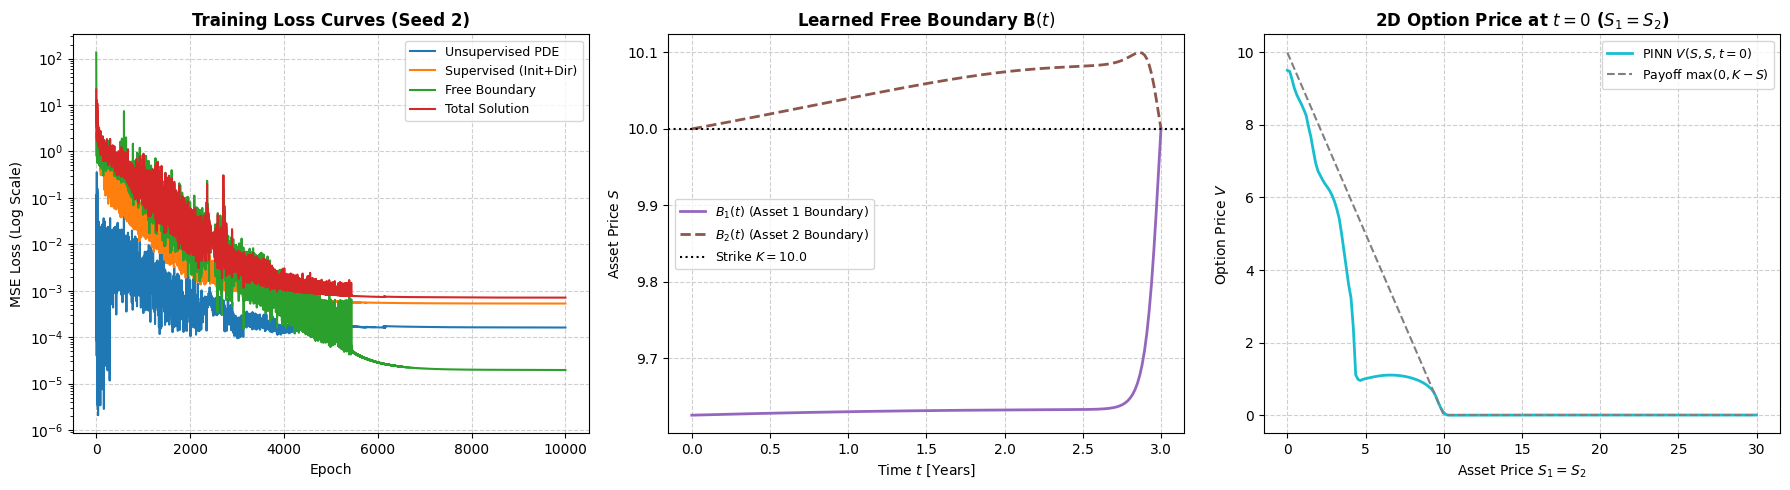

In [21]:
def evaluate_test_set(model, n_test_pde=1000000, n_test_bnd=1000):
    """Evaluates the trained model on an independent uniform test set."""
    print(f"Generating independent test set ({n_test_pde} PDE points, {n_test_bnd} boundary points)...")

    # 1. FB Initial
    t_fb_init_test = tf.constant([[T]], dtype=tf.float32)
    y_fb_init_test = tf.constant([[K, K]], dtype=tf.float32)
    fb_init_pred = model.fb(t_fb_init_test, training=False)
    test_fb_init_loss = tf.reduce_mean(tf.square(fb_init_pred - y_fb_init_test)).numpy()

    # 2. FB Dirichlet
    t_fb_dir_test = sample_uniform_points(1, n_test_bnd, np.array([0.0], dtype=np.float32), np.array([T], dtype=np.float32))
    s_val_dir = model.fb(t_fb_dir_test, training=False)
    fb_dc = model.mdl(tf.concat([s_val_dir, t_fb_dir_test], axis=1), training=False)
    fb_dir_tgt = tf.nn.relu(K - tf.reduce_min(s_val_dir, axis=1, keepdims=True))
    test_fb_dir_loss = tf.reduce_mean(tf.square(fb_dc - fb_dir_tgt)).numpy()

    # 3. FB Neumann
    t_fb_neu_test = sample_uniform_points(1, n_test_bnd, np.array([0.0], dtype=np.float32), np.array([T], dtype=np.float32))
    s_val_neu = model.fb(t_fb_neu_test, training=False)
    with tf.GradientTape() as neu_tape:
        neu_tape.watch(s_val_neu)
        pinn_nc_fb = model.mdl(tf.concat([s_val_neu, t_fb_neu_test], axis=1), training=False)
    pinn_nc_fb = neu_tape.gradient(pinn_nc_fb, s_val_neu)
    fb_neu_tgt = -tf.one_hot(tf.argmin(s_val_neu, axis=1), depth=2)
    test_fb_neu_loss = tf.reduce_mean(tf.square(pinn_nc_fb - fb_neu_tgt)).numpy()

    test_fb_loss = test_fb_init_loss + test_fb_dir_loss + test_fb_neu_loss

    # 4. Initial Condition
    init_spatial_test = sample_uniform_points(2, n_test_bnd, lb[:2], ub[:2])
    x_init_test = tf.concat([init_spatial_test, tf.fill((n_test_bnd, 1), T)], axis=1)
    y_init_test = tf.nn.relu(K - tf.reduce_min(x_init_test[:, :2], axis=1))
    pinn_init_test = model.mdl(x_init_test, training=False)
    test_init_loss = tf.reduce_mean(tf.square(tf.squeeze(pinn_init_test) - y_init_test)).numpy()

    # 5. Dirichlet Condition (Half on S1=30, half on S2=30)
    n_half_t = n_test_bnd // 2
    dir1_t = sample_uniform_points(2, n_half_t, np.array([0.0, 0.0], dtype=np.float32), np.array([S_max, T], dtype=np.float32))
    face1_t = tf.concat([tf.fill((n_half_t, 1), S_max), dir1_t[:, 0:1], dir1_t[:, 1:2]], axis=1)
    dir2_t = sample_uniform_points(2, n_half_t, np.array([0.0, 0.0], dtype=np.float32), np.array([S_max, T], dtype=np.float32))
    face2_t = tf.concat([dir2_t[:, 0:1], tf.fill((n_half_t, 1), S_max), dir2_t[:, 1:2]], axis=1)
    x_dir_test = tf.concat([face1_t, face2_t], axis=0)
    y_dir_test = tf.nn.relu(K * tf.exp(-r * (T - x_dir_test[:, 2])) - tf.reduce_min(x_dir_test[:, :2], axis=1))
    pinn_dir_test = model.mdl(x_dir_test, training=False)
    test_dir_loss = tf.reduce_mean(tf.square(tf.squeeze(pinn_dir_test) - y_dir_test)).numpy()

    # 6. Unsupervised PDE Loss (Evaluated in chunks of 50,000 points to ensure safe GPU memory)
    chunk_size = 50000
    num_chunks = n_test_pde // chunk_size
    pde_sq_errors = []

    for _ in range(num_chunks):
        test_chunk = sample_uniform_points(3, chunk_size, lb, ub)
        x_chunk = test_chunk[:, :2]
        t_chunk = test_chunk[:, 2:3]

        s_val_chunk = model.fb(t_chunk, training=False)
        in_cont = tf.reduce_all(x_chunk >= s_val_chunk, axis=1)
        x_c = tf.boolean_mask(x_chunk, in_cont)
        t_c = tf.boolean_mask(t_chunk, in_cont)

        if tf.shape(x_c)[0] == 0:
            continue

        S1_c = x_c[:, 0:1]
        S2_c = x_c[:, 1:2]
        t_c_var = tf.reshape(t_c[:, 0], (-1, 1))

        with tf.GradientTape(persistent=True) as tape2:
            tape2.watch([S1_c, S2_c, t_c_var])
            with tf.GradientTape(persistent=True) as tape1:
                tape1.watch([S1_c, S2_c, t_c_var])
                u_v = model.mdl(tf.concat([S1_c, S2_c, t_c_var], axis=1), training=False)
            u_s1 = tape1.gradient(u_v, S1_c)
            u_s2 = tape1.gradient(u_v, S2_c)
            u_t  = tape1.gradient(u_v, t_c_var)

        u_s1s1 = tape2.gradient(u_s1, S1_c)
        u_s2s2 = tape2.gradient(u_s2, S2_c)
        u_s1s2 = tape2.gradient(u_s1, S2_c)
        del tape1
        del tape2

        res = (
            u_t
            + (r - q) * S1_c * u_s1
            + (r - q) * S2_c * u_s2
            + 0.5 * alphas_tf[0, 0] * (S1_c**2) * u_s1s1
            + alphas_tf[0, 1] * (S1_c * S2_c) * u_s1s2
            + 0.5 * alphas_tf[1, 1] * (S2_c**2) * u_s2s2
            - r * u_v
        )
        pde_sq_errors.append(tf.reduce_mean(tf.square(res)).numpy())

    test_unsup_loss = float(np.mean(pde_sq_errors))
    test_sol_loss = test_unsup_loss + test_init_loss + test_dir_loss + test_fb_dir_loss + test_fb_neu_loss

    return {
        'Unsupervised': test_unsup_loss,
        'Initial': test_init_loss,
        'Dirichlet': test_dir_loss,
        'FB_Init': test_fb_init_loss,
        'FB_Dir': test_fb_dir_loss,
        'FB_Neu': test_fb_neu_loss,
        'Free boundary': test_fb_loss,
        'Solution': test_sol_loss
    }

# Compute test metrics for Seed 2
seed2_test_metrics = evaluate_test_set(pinn_model_seed2)
seed2_test_metrics['Seed'] = seed_to_run
seed2_test_metrics['Training Time (s)'] = elapsed_time
results_2d.append(seed2_test_metrics)

df_seed2 = pd.DataFrame([seed2_test_metrics])
print("\n" + "=" * 70)
print("COMPUTED TEST METRICS FOR SEED 2 (TABLE 6 PROTOCOL)")
print("=" * 70)
display(df_seed2)

# Paper Reference Values (Table 6)
paper_seed2_ref = {
    'Unsupervised': 0.001313,
    'Initial': 0.000570,
    'Dirichlet': 0.000199,
    'FB_Init': 0.000000,
    'FB_Dir': 0.000029,
    'FB_Neu': 0.000008,
    'Free boundary': 0.000037,
    'Solution': 0.002120
}

comp_rows = []
for m in ['Unsupervised', 'Initial', 'Dirichlet', 'FB_Init', 'FB_Dir', 'FB_Neu', 'Free boundary', 'Solution']:
    comp_rows.append({
        'Metric': m,
        'Our Computed (Seed 2)': seed2_test_metrics[m],
        'Paper Seed 2 Reference': paper_seed2_ref[m]
    })

df_comp = pd.DataFrame(comp_rows)
print("\n" + "=" * 70)
print("COMPARISON WITH PAPER SEED 2 REFERENCE VALUES")
print("=" * 70)
display(df_comp)

# Visualizations
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# 1. Loss convergence
hist = pinn_model_seed2.history
axs[0].semilogy(hist['epoch'], hist['unsup'], label='Unsupervised PDE', color='#1f77b4', lw=1.5)
axs[0].semilogy(hist['epoch'], np.array(hist['init']) + np.array(hist['dir']), label='Supervised (Init+Dir)', color='#ff7f0e', lw=1.5)
axs[0].semilogy(hist['epoch'], hist['free_boundary'], label='Free Boundary', color='#2ca02c', lw=1.5)
axs[0].semilogy(hist['epoch'], hist['solution'], label='Total Solution', color='#d62728', lw=1.5)
axs[0].set_title("Training Loss Curves (Seed 2)", fontsize=12, fontweight='bold')
axs[0].set_xlabel("Epoch", fontsize=10)
axs[0].set_ylabel("MSE Loss (Log Scale)", fontsize=10)
axs[0].grid(True, linestyle='--', alpha=0.6)
axs[0].legend(fontsize=9)

# 2. Learned Free Boundary Trajectories
t_eval = np.linspace(0.0, T, 200).reshape(-1, 1).astype(np.float32)
B_pred = pinn_model_seed2.fb(t_eval, training=False).numpy()
axs[1].plot(t_eval, B_pred[:, 0], label='$B_1(t)$ (Asset 1 Boundary)', color='#9467bd', lw=2.0)
axs[1].plot(t_eval, B_pred[:, 1], label='$B_2(t)$ (Asset 2 Boundary)', color='#8c564b', lw=2.0, linestyle='--')
axs[1].axhline(y=K, color='black', linestyle=':', label='Strike $K=10.0$')
axs[1].set_title("Learned Free Boundary $\\mathbf{B}(t)$", fontsize=12, fontweight='bold')
axs[1].set_xlabel("Time $t$ [Years]", fontsize=10)
axs[1].set_ylabel("Asset Price $S$", fontsize=10)
axs[1].grid(True, linestyle='--', alpha=0.6)
axs[1].legend(fontsize=9)

# 3. Option Price Slice at t=0
s_diag = np.linspace(0.0, S_max, 200).astype(np.float32)
t_zero = np.zeros_like(s_diag).reshape(-1, 1)
inp_diag = np.column_stack([s_diag, s_diag, t_zero])
V_diag = pinn_model_seed2.mdl(inp_diag, training=False).numpy().flatten()
payoff_diag = np.maximum(0.0, K - s_diag)
axs[2].plot(s_diag, V_diag, label='PINN $V(S, S, t=0)$', color='#17becf', lw=2.0)
axs[2].plot(s_diag, payoff_diag, label='Payoff $\\max(0, K-S)$', color='gray', linestyle='--', lw=1.5)
axs[2].set_title("2D Option Price at $t=0$ ($S_1=S_2$)", fontsize=12, fontweight='bold')
axs[2].set_xlabel("Asset Price $S_1 = S_2$", fontsize=10)
axs[2].set_ylabel("Option Price $V$", fontsize=10)
axs[2].grid(True, linestyle='--', alpha=0.6)
axs[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

In [22]:
ALL_SEEDS = [2, 3, 5, 7, 11, 13, 17, 19, 23, 29]
trained_2d_models = {}
results_2d = []
total_epochs = 10000
n_steps = 4

header_fmt = "{:<8} | {:<11} | {:<11} | {:<11} | {:<11} | {:<11} | {:<11} | {:<13} | {:<11}"
row_fmt    = "{:<8} | {:<11.6f} | {:<11.6f} | {:<11.6f} | {:<11.6f} | {:<11.6f} | {:<11.6f} | {:<13.6f} | {:<11.6f}"

print("=" * 105)
print("STARTING FULL 10-SEED 2D EXPERIMENT REPRODUCTION (TABLE 6)")
print("=" * 105)

overall_start = time.time()

for seed_idx, seed in enumerate(ALL_SEEDS, 1):
    print(f"\n" + "#" * 105)
    print(f"RUNNING SEED {seed} ({seed_idx}/10) — 10,000 EPOCHS, N_steps=4, 60,000 SOBOL PDE POINTS")
    print("#" * 105)
    print(header_fmt.format('Epoch', 'Unsupervised', 'Initial', 'Dirichlet', 'FB_Init', 'FB_Dir', 'FB_Neu', 'Free Boundary', 'Solution'))
    print("-" * 105)

    t0 = time.time()
    model_seed = AmericanOptionPINN_2D(seed=seed)

    for epoch in range(1, total_epochs + 1):
        u_l, i_l, d_l, bi_l, bd_l, bn_l, fb_l, sol_l = model_seed.train_epoch(
            x_f_total, t_f_total, x_init, y_init, x_dir, y_dir, t_fb_init, y_fb_init, t_fb_dir, t_fb_neu, epoch=epoch, n_steps=n_steps
        )

        if epoch == 1 or epoch % 2000 == 0 or epoch == total_epochs:
            print(row_fmt.format(epoch, u_l, i_l, d_l, bi_l, bd_l, bn_l, fb_l, sol_l))

    elapsed = time.time() - t0
    print("-" * 105)
    print(f"Seed {seed} training completed in {elapsed:.2f}s ({elapsed/60:.2f} min).")

    # Restore optimal model state
    model_seed.restore_best_weights()
    trained_2d_models[seed] = model_seed

    # Evaluate on independent 1,000,000-point uniform test set
    test_metrics = evaluate_test_set(model_seed)
    test_metrics['Seed'] = seed
    test_metrics['Training Time (s)'] = elapsed
    results_2d.append(test_metrics)

    print(f">>> SEED {seed} TEST METRICS: Solution={test_metrics['Solution']:.6f} | FB={test_metrics['Free boundary']:.6f} | PDE={test_metrics['Unsupervised']:.6f}")

total_time = time.time() - overall_start
print("\n" + "=" * 105)
print(f"ALL 10 SEEDS COMPLETED IN {total_time:.2f}s ({total_time/60:.2f} min)!")
print("=" * 105)


STARTING FULL 10-SEED 2D EXPERIMENT REPRODUCTION (TABLE 6)

#########################################################################################################
RUNNING SEED 2 (1/10) — 10,000 EPOCHS, N_steps=4, 60,000 SOBOL PDE POINTS
#########################################################################################################
Epoch    | Unsupervised | Initial     | Dirichlet   | FB_Init     | FB_Dir      | FB_Neu      | Free Boundary | Solution   
---------------------------------------------------------------------------------------------------------
1        | 0.109223    | 39.396832   | 39.658184   | 99.089233   | 23.338364   | 0.569174    | 122.996773    | 189.018188 
2000     | 0.000555    | 0.003481    | 0.002380    | 0.012301    | 0.007373    | 0.004158    | 0.023832      | 0.016647   
4000     | 0.000238    | 0.000470    | 0.000224    | 0.004789    | 0.000297    | 0.003649    | 0.008735      | 0.005399   
6000     | 0.000160    | 0.000382    | 0.000169    | 0.

In [23]:

import numpy as np
import pandas as pd

table6_rows = []

# Evaluate the already restored best model for each seed on the training collocation points
for seed in ALL_SEEDS:
    model = trained_2d_models[seed]

    # Evaluate the 8 loss components on the training points using the restored weights
    u_l, i_l, d_l, bi_l, bd_l, bn_l, fb_l, sol_l = model.train_step_joint(
        x_f_total, t_f_total, x_init, y_init, x_dir, y_dir,
        t_fb_init, y_fb_init, t_fb_dir, t_fb_neu
    )

    unsup = float(u_l.numpy())
    init  = float(i_l.numpy())
    dir_l = float(d_l.numpy())
    fb_i  = float(bi_l.numpy())
    fb_d  = float(bd_l.numpy())
    fb_n  = float(bn_l.numpy())

    # Formulas from paper (Eqs. 34 & 40)
    free_bnd = fb_i + fb_d + fb_n
    solution = unsup + init + dir_l + fb_d + fb_n

    table6_rows.append([seed, unsup, init, dir_l, fb_i, fb_d, fb_n, free_bnd, solution])

# Construct DataFrame
cols = ['Seed', 'Unsupervised', 'Initial', 'Dirichlet', 'FB_Init', 'FB_Dir', 'FB_Neu', 'Free boundary', 'Solution']
table6_2d = pd.DataFrame(table6_rows, columns=cols)

# Compute Mean and Median summary rows
mean_row   = ['Mean'] + [table6_2d[c].mean() for c in cols[1:]]
median_row = ['Median'] + [table6_2d[c].median() for c in cols[1:]]

# Append statistics to create final Table 6
table6_2d = pd.concat([table6_2d, pd.DataFrame([mean_row, median_row], columns=cols)], ignore_index=True)

# Display formatted to 6 decimal places
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
print(table6_2d.to_string(index=False))


  Seed  Unsupervised  Initial  Dirichlet  FB_Init   FB_Dir   FB_Neu  Free boundary  Solution
     2      0.000144 0.000322   0.000148 0.000000 0.000010 0.000013       0.000023  0.000637
     3      0.000361 0.000462   0.000314 0.000000 0.000004 0.000330       0.000334  0.001472
     5      0.000452 0.000641   0.000319 0.000000 0.000019 0.000032       0.000051  0.001463
     7      0.000184 0.000344   0.000174 0.000000 0.000017 0.000008       0.000024  0.000727
    11      0.000389 0.000324   0.000157 0.000000 0.000011 0.000027       0.000038  0.000909
    13      0.000120 0.000346   0.000183 0.000000 0.000039 0.000012       0.000052  0.000701
    17      0.000415 0.000574   0.000361 0.000000 0.000072 0.000020       0.000092  0.001442
    19      0.000154 0.000258   0.000115 0.000000 0.000008 0.000010       0.000018  0.000545
    23      0.000114 0.000433   0.000322 0.000000 0.000010 0.000006       0.000017  0.000885
    29      0.000095 0.000338   0.000227 0.000000 0.000017 0.000006   

In [25]:
print(fb_i + fb_d + fb_n)
print(unsup + init + dir_l + fb_d + fb_n)

2.3287851490749745e-05
0.0006839157417743991
